In [1]:
import pandas as pd
df = pd.read_csv('/Users/partha/Documents/AI Lab/Equties Volatility Project/data/archive/ABB_5minute.csv')
df.head()
print(len(df))

206794


# Pandas for Data Preparation & EDA — A Step-by-Step Learning Notebook


### Dataset used
We use the classic **Titanic passenger dataset**, loaded directly from a public GitHub CSV:

> `https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv`

This is one of the most widely used beginner datasets for pandas/EDA practice (891 passengers, mix of numeric, categorical, and missing data — perfect for demonstrating cleaning and EDA techniques). If your machine has no internet access, the setup cell below automatically falls back to `seaborn`'s built-in copy of the same dataset.

**Alternative sources for the same dataset** (in case the link above ever changes):
- Kaggle: https://www.kaggle.com/c/titanic/data
- Seaborn built-in: `seaborn.load_dataset('titanic')`

---
### How to use this notebook
- Run cells from top to bottom.
- Read the **Theory** cell, run the **Example** cell and study the output, then attempt the **Task** cell yourself before checking any hints.
- Task cells contain `# TODO` comments — replace them with your own code.


## 0. Setup

Run this cell first. It imports the libraries we need and loads the Titanic dataset (with an offline fallback).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

try:
    df_raw = pd.read_csv(DATA_URL)
    print("Loaded dataset from URL.")
except Exception as e:
    print("Could not reach the URL (", e, "). Falling back to seaborn's built-in Titanic dataset.")
    df_raw = sns.load_dataset('titanic')
    # Rename columns to match the Kaggle/GitHub version used throughout this notebook
    df_raw = df_raw.rename(columns={
        'survived': 'Survived', 'pclass': 'Pclass', 'sex': 'Sex', 'age': 'Age',
        'sibsp': 'SibSp', 'parch': 'Parch', 'fare': 'Fare', 'embarked': 'Embarked',
        'class': 'Class', 'who': 'Who', 'deck': 'Deck', 'embark_town': 'Embark_town'
    })

df = df_raw.copy()
print("Shape:", df.shape)
df.head()


Loaded dataset from URL.
Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Pandas Data Structures: `Series` and `DataFrame`

### Theory
Pandas has two core data structures:

- **`Series`**: a one-dimensional labeled array — think of a single column with an index.
- **`DataFrame`**: a two-dimensional labeled table — think of a spreadsheet, made up of multiple `Series` sharing the same index.

Every `DataFrame` column is technically a `Series`. Understanding this relationship helps you move fluidly between selecting a single column and working with the whole table.


In [3]:
# EXAMPLE
# A Series: one column of the Titanic data
age_series = df['Age']
print(type(age_series))
print(age_series.head())

# A DataFrame: the whole table (or a subset of columns)
subset_df = df[['Name', 'Age', 'Sex']]
print(type(subset_df))
subset_df.head()

<class 'pandas.core.series.Series'>
0    22.0
1    38.0
2    26.0
3    35.0
4    35.0
Name: Age, dtype: float64
<class 'pandas.core.frame.DataFrame'>


,Name,Age,Sex
0,"Braund, Mr. Owen Harris",22.0,male
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,female
2,"Heikkinen, Miss. Laina",26.0,female
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,female
4,"Allen, Mr. William Henry",35.0,male


### Task 1
1. Create a `Series` called `fare_series` containing only the `Fare` column.
2. Create a `DataFrame` called `basic_info` containing the columns `Name`, `Pclass`, and `Survived`.
3. Print the `type()` of each to confirm they are a `Series` and `DataFrame` respectively.

In [4]:
# TODO: create fare_series (a Series of the 'Fare' column)
fare_series = df['Fare']
# TODO: create basic_info (a DataFrame with 'Name', 'Pclass', 'Survived')
basic_info = df[['Name', 'Pclass', 'Survived']]

# TODO: print the type of each variable
print(type(fare_series))
print(type(basic_info))

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>


## 2. Loading Data

### Theory
Pandas can read many file formats: `read_csv()`, `read_excel()`, `read_json()`, `read_sql()`, etc. The most common function you'll use is `pd.read_csv()`, which accepts either a local file path or a URL. Useful arguments include:

- `sep` — delimiter (default `,`)
- `usecols` — load only specific columns (saves memory)
- `index_col` — set a column as the row index
- `na_values` — extra strings to treat as missing (`NaN`)


In [5]:
# EXAMPLE
# We already loaded the full dataset into df_raw / df above using pd.read_csv(DATA_URL)
# Here we demonstrate loading only a subset of columns, for illustration:
df_subset_load = pd.read_csv(DATA_URL, usecols=['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'Fare']) \
    if DATA_URL else None
try:
    print(df_subset_load.head())
except Exception:
    print("(Skipped — using offline fallback dataset already loaded as df)")


   PassengerId  Survived  Pclass     Sex   Age     Fare
0            1         0       3    male  22.0   7.2500
1            2         1       1  female  38.0  71.2833
2            3         1       3  female  26.0   7.9250
3            4         1       1  female  35.0  53.1000
4            5         0       3    male  35.0   8.0500


### Task 2
Using `pd.read_csv()` on `DATA_URL` (or reusing `df` if you are offline), load the dataset again but this time:
1. Only load the columns `Name`, `Sex`, `Age`, `Survived`.
2. Set `Name` as the index column using `index_col`.

Store the result in a variable called `df_named`.

In [6]:
# TODO: load the dataset with only Name, Sex, Age, Survived columns, indexed by Name
df_named = df[['Name', 'Sex', 'Age', 'Survived']].set_index('Name')
df_named.head()


,Sex,Age,Survived
Name,,,
"Braund, Mr. Owen Harris",male,22.0,0
"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1
"Heikkinen, Miss. Laina",female,26.0,1
"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1
"Allen, Mr. William Henry",male,35.0,0


## 3. Initial Data Inspection

### Theory
Before touching any data, always get an overview:

- `df.head(n)` / `df.tail(n)` — first/last n rows
- `df.shape` — (rows, columns)
- `df.info()` — dtypes, non-null counts, memory usage
- `df.describe()` — summary statistics for numeric columns (`include='all'` for all columns)
- `df.dtypes` — data type of each column
- `df.columns` — column names


In [7]:
# EXAMPLE
print("Shape:", df.shape)
print("\nColumn dtypes:\n", df.dtypes)
print()
df.info()


Shape: (891, 12)

Column dtypes:
 PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 no

In [8]:
# EXAMPLE (continued)
df.describe()  # numeric summary


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
# EXAMPLE (continued)
df.describe(include='all').T  # summary for ALL columns, transposed for readability


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


### Task 3
1. Print the last 7 rows of `df` using `.tail()`.
2. Print the number of rows and columns separately (not as a tuple) using `.shape`.
3. Run `.describe()` on just the `Fare` and `Age` columns.

In [10]:
# TODO: print last 7 rows
df.tail()
# TODO: print number of rows and number of columns separately
print(df.shape[0])
print(df.shape[1])
# TODO: describe() on just Fare and Age
df[['Fare', 'Age']].describe()

891
12


,Fare,Age
count,891.000000,714.000000
mean,32.204208,29.699118
std,49.693429,14.526497
min,0.000000,0.420000
25%,7.910400,20.125000
50%,14.454200,28.000000
75%,31.000000,38.000000
max,512.329200,80.000000


## 4. Handling Missing Data

### Theory
Real-world data almost always has missing values (`NaN`). Key tools:

- `df.isnull()` / `df.isna()` — boolean mask of missing values
- `df.isnull().sum()` — count of missing values per column
- `df.dropna()` — remove rows/columns with missing values
- `df.fillna(value)` — fill missing values (a constant, mean/median, or method like `ffill`)

Choosing **drop vs. fill** depends on how much data is missing and why. A column missing 80% of its values (like `Cabin` here) is often better dropped; a column missing 20% (like `Age`) is often better imputed.


In [11]:
# EXAMPLE
missing_counts = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(1)
missing_summary = pd.DataFrame({'missing_count': missing_counts, 'missing_pct': missing_pct})
missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_pct', ascending=False)


,missing_count,missing_pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


In [12]:
# EXAMPLE (continued): a common cleaning strategy for this dataset
df_clean = df.copy()

# Age: numeric, moderately missing -> fill with median
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

# Embarked: categorical, only a couple missing -> fill with mode (most frequent value)
if 'Embarked' in df_clean.columns:
    df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

# Cabin: mostly missing -> drop the column entirely
if 'Cabin' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Cabin'])

print(df_clean.isnull().sum())


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


### Task 4
Starting from `df` (not `df_clean`):
1. Compute how many missing values exist in the `Fare` column.
2. Fill missing `Fare` values with the **mean** fare (store the result back into a new DataFrame `df_task4`).
3. Confirm there are 0 missing values left in `Fare` afterwards.

In [13]:
# TODO: count missing Fare values
df['Fare'].isnull().sum()
# TODO: create df_task4 = df.copy(), then fill missing Fare with the mean
df_task4 = df.copy()
df_task4['Fare'].fillna(df_task4['Fare'].mean(), inplace=True)
# TODO: confirm 0 missing values remain in Fare
df_task4['Fare'].isnull().sum()

/var/folders/zd/zwmpxg4d4gnf39z3h69y43bm0000gn/T/ipykernel_28731/1466629145.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_task4['Fare'].fillna(df_task4['Fare'].mean(), inplace=True)


np.int64(0)

## 5. Handling Duplicate Rows

### Theory
Duplicate rows can skew analysis (e.g., double-counting a passenger). Useful tools:

- `df.duplicated()` — boolean mask of duplicate rows (keeps first occurrence as `False`)
- `df.duplicated().sum()` — count of duplicate rows
- `df.drop_duplicates()` — remove duplicate rows (`subset=[...]` to check specific columns only)


In [14]:
# EXAMPLE
print("Number of fully duplicated rows:", df.duplicated().sum())

# Check for duplicates based on a subset of columns, e.g. same Name (shouldn't normally happen)
print("Duplicate Names:", df.duplicated(subset=['Name']).sum())


Number of fully duplicated rows: 0
Duplicate Names: 0


### Task 5
1. Check how many duplicate rows exist when considering only the `Ticket` column (some passengers share tickets — e.g., families).
2. Create `df_no_dupe_tickets` that keeps only the **first** occurrence of each `Ticket`.
3. Print the shape of `df` vs. `df_no_dupe_tickets` to confirm rows were removed.

In [15]:
# TODO: count duplicated Ticket values

# TODO: drop_duplicates on 'Ticket', keep first occurrence
df_no_dupe_tickets = None

# TODO: print df.shape vs df_no_dupe_tickets.shape


## 6. Data Type Conversion

### Theory
Correct dtypes matter for both correctness and memory efficiency:

- `df.astype(dtype)` — convert a column's type (e.g., `int`, `float`, `str`, `category`)
- `pd.to_numeric()` / `pd.to_datetime()` — safer conversions that handle errors (`errors='coerce'` turns invalid values into `NaN`)
- Converting low-cardinality text columns (like `Sex`, `Embarked`) to the `category` dtype saves memory and speeds up groupby operations.


In [16]:
# EXAMPLE
df_types = df.copy()

# Survived and Pclass are really categorical labels, not continuous numbers
df_types['Survived'] = df_types['Survived'].astype('category')
df_types['Pclass'] = df_types['Pclass'].astype('category')

# Sex and Embarked are also good candidates for 'category'
df_types['Sex'] = df_types['Sex'].astype('category')

print(df_types.dtypes)
print("\nMemory usage before vs after (bytes):")
print("Original Sex column:", df['Sex'].memory_usage(deep=True))
print("Category Sex column:", df_types['Sex'].memory_usage(deep=True))


PassengerId       int64
Survived       category
Pclass         category
Name             object
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket           object
Fare            float64
Cabin            object
Embarked         object
dtype: object

Memory usage before vs after (bytes):
Original Sex column: 47983
Category Sex column: 1239


### Task 6
1. Convert the `Embarked` column of `df` to `category` dtype and store in a new DataFrame `df_task6`.
2. Compare the memory usage (`memory_usage(deep=True)`) of the original `Embarked` column vs. the converted one.

In [17]:
# TODO: create df_task6, convert Embarked to category dtype
df_task6 = None

# TODO: compare memory usage before vs after


## 7. Filtering & Selecting Data

### Theory
- `df['col']` or `df.col` — select a single column
- `df[['col1', 'col2']]` — select multiple columns
- `df.loc[row_labels, col_labels]` — label-based selection
- `df.iloc[row_positions, col_positions]` — position-based selection
- Boolean indexing: `df[df['col'] > value]` — filter rows matching a condition
- Combine conditions with `&` (and), `|` (or) — each condition wrapped in parentheses


In [18]:
# EXAMPLE
# Boolean filter: female passengers in 1st class
first_class_women = df[(df['Sex'] == 'female') & (df['Pclass'] == 1)]
print("Count:", len(first_class_women))
first_class_women[['Name', 'Age', 'Survived']].head()


Count: 94


,Name,Age,Survived
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1
11,"Bonnell, Miss. Elizabeth",58.0,1
31,"Spencer, Mrs. William Augustus (Marie Eugenie)",NaN,1
52,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",49.0,1


In [19]:
# EXAMPLE (continued): .loc vs .iloc
print(df.loc[0:4, ['Name', 'Age']])   # label-based: rows 0-4 inclusive, specific columns
print()
print(df.iloc[0:5, 3:6])              # position-based: first 5 rows, columns at positions 3-5


                                                Name   Age
0                            Braund, Mr. Owen Harris  22.0
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0
2                             Heikkinen, Miss. Laina  26.0
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0
4                           Allen, Mr. William Henry  35.0

                                                Name     Sex   Age
0                            Braund, Mr. Owen Harris    male  22.0
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0
2                             Heikkinen, Miss. Laina  female  26.0
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0
4                           Allen, Mr. William Henry    male  35.0


### Task 7
1. Select all passengers who are **male**, **older than 60**, using boolean indexing.
2. Select just the `Name` and `Age` columns of that filtered result.
3. Using `.iloc`, select the first 10 rows and the first 3 columns of `df`.

In [20]:
# TODO: filter male passengers older than 60
elderly_men = None

# TODO: select just Name and Age columns from elderly_men

# TODO: use .iloc to get first 10 rows, first 3 columns of df


## 8. Sorting & Ranking

### Theory
- `df.sort_values('col', ascending=True/False)` — sort rows by column value(s)
- `df.sort_values(['col1', 'col2'])` — sort by multiple columns (priority order)
- `df.sort_index()` — sort rows by index
- `df['col'].rank()` — assign ranks to values


In [21]:
# EXAMPLE
oldest_passengers = df.sort_values('Age', ascending=False)
oldest_passengers[['Name', 'Age', 'Pclass']].head()


,Name,Age,Pclass
630,"Barkworth, Mr. Algernon Henry Wilson",80.0,1
851,"Svensson, Mr. Johan",74.0,3
493,"Artagaveytia, Mr. Ramon",71.0,1
96,"Goldschmidt, Mr. George B",71.0,1
116,"Connors, Mr. Patrick",70.5,3


In [22]:
# EXAMPLE (continued): sort by multiple columns
df.sort_values(['Pclass', 'Fare'], ascending=[True, False])[['Name', 'Pclass', 'Fare']].head(10)


,Name,Pclass,Fare
258,"Ward, Miss. Anna",1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
737,"Lesurer, Mr. Gustave J",1,512.3292
27,"Fortune, Mr. Charles Alexander",1,263.0000
88,"Fortune, Miss. Mabel Helen",1,263.0000
341,"Fortune, Miss. Alice Elizabeth",1,263.0000
438,"Fortune, Mr. Mark",1,263.0000
311,"Ryerson, Miss. Emily Borie",1,262.3750
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750
118,"Baxter, Mr. Quigg Edmond",1,247.5208


### Task 8
1. Sort passengers by `Fare` in descending order and show the top 5 `Name`, `Fare`, `Pclass`.
2. Sort passengers first by `Survived` (descending) then by `Age` (ascending), show the top 10 rows.

In [23]:
# TODO: sort by Fare descending, show top 5 (Name, Fare, Pclass)
df.sort_values('Fare', ascending=False).head(5)[['Name', 'Fare', 'Pclass']]
# TODO: sort by Survived desc then Age asc, show top 10
df.sort_values(['Survived', 'Age'], ascending=[False, True]).head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C
755,756,1,2,"Hamalainen, Master. Viljo",male,0.67,1,1,250649,14.5000,NaN,S
469,470,1,3,"Baclini, Miss. Helene Barbara",female,0.75,2,1,2666,19.2583,NaN,C
644,645,1,3,"Baclini, Miss. Eugenie",female,0.75,2,1,2666,19.2583,NaN,C
78,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,248738,29.0000,NaN,S
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,29106,18.7500,NaN,S
305,306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S
172,173,1,3,"Johnson, Miss. Eleanor Ileen",female,1.00,1,1,347742,11.1333,NaN,S
183,184,1,2,"Becker, Master. Richard F",male,1.00,2,1,230136,39.0000,F4,S
381,382,1,3,"Nakid, Miss. Maria (""Mary"")",female,1.00,0,2,2653,15.7417,NaN,C


## 9. GroupBy & Aggregation

### Theory
`df.groupby('col')` splits data into groups based on a column's values, so you can apply aggregate functions per group ("split-apply-combine"):

- `.mean()`, `.sum()`, `.count()`, `.median()`, `.std()`
- `.agg({'col': 'func'})` — apply different aggregations to different columns
- `.size()` — number of rows per group (includes NaNs, unlike `.count()`)


In [24]:
# EXAMPLE
# Survival rate by passenger class
survival_by_class = df.groupby('Pclass')['Survived'].mean()
print(survival_by_class)


Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [25]:
# EXAMPLE (continued): multiple aggregations at once
summary = df.groupby(['Pclass', 'Sex']).agg(
    avg_age=('Age', 'mean'),
    avg_fare=('Fare', 'mean'),
    survival_rate=('Survived', 'mean'),
    count=('Survived', 'size')
).round(2)
summary


avg_age  avg_fare  survival_rate  count
Pclass Sex                                            
1      female    34.61    106.13           0.97     94
       male      41.28     67.23           0.37    122
2      female    28.72     21.97           0.92     76
       male      30.74     19.74           0.16    108
3      female    21.75     16.12           0.50    144
       male      26.51     12.66           0.14    347

### Task 9
1. Group by `Embarked` and compute the average `Fare` per embarkation port.
2. Group by `Sex` and compute both the average `Age` and the survival rate (`Survived` mean) in a single `.agg()` call.

In [39]:
# TODO: average Fare grouped by Embarked
df.groupby('Embarked')['Fare'].mean()
# TODO: average Age and survival rate grouped by Sex, using .agg()
df.groupby('Sex').agg({'Age': 'mean', 'Survived': 'mean'})

,Age,Survived
Sex,,
female,27.915709,0.742038
male,30.726645,0.188908


## 10. Creating New Features (`apply`, `map`, vectorized ops)

### Theory
Feature engineering means deriving new, more useful columns from existing ones:

- Vectorized arithmetic: `df['a'] + df['b']` (fastest — prefer this when possible)
- `.map()` — element-wise mapping for a `Series` (e.g., dictionary lookup)
- `.apply(func)` — apply a custom function row-wise or element-wise (slower, but flexible)
- `pd.cut()` — bin continuous values into discrete categories


In [40]:
# EXAMPLE
df_feat = df.copy()

# Vectorized: family size = siblings/spouses + parents/children + self
df_feat['FamilySize'] = df_feat['SibSp'] + df_feat['Parch'] + 1

# map(): convert numeric Survived into readable labels
df_feat['SurvivedLabel'] = df_feat['Survived'].map({0: 'No', 1: 'Yes'})

# apply(): custom function extracting title from Name (e.g., 'Mr', 'Mrs', 'Miss')
def extract_title(name):
    return name.split(',')[1].split('.')[0].strip()

df_feat['Title'] = df_feat['Name'].apply(extract_title)

# pd.cut(): bin Age into groups
df_feat['AgeGroup'] = pd.cut(df_feat['Age'], bins=[0, 12, 18, 35, 60, 100],
                              labels=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'])

df_feat[['Name', 'FamilySize', 'SurvivedLabel', 'Title', 'AgeGroup']].head()


,Name,FamilySize,SurvivedLabel,Title,AgeGroup
0,"Braund, Mr. Owen Harris",2,No,Mr,YoungAdult
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",2,Yes,Mrs,Adult
2,"Heikkinen, Miss. Laina",1,Yes,Miss,YoungAdult
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",2,Yes,Mrs,YoungAdult
4,"Allen, Mr. William Henry",1,No,Mr,YoungAdult


### Task 10
1. Create a new column `IsAlone` that is `True` when `FamilySize == 1`, else `False` (hint: use a vectorized comparison, no need for `.apply()`).
2. Create a new column `FareGroup` that bins `Fare` into 4 categories using `pd.qcut()` (equal-sized bins) labeled `Low`, `Medium`, `High`, `VeryHigh`.

In [47]:
# TODO: create FareGroup using pd.qcut with 4 bins, labeled Low/Medium/High/VeryHigh
df['FareGroup'] = pd.qcut(df['Fare'], q=4, labels=['Low', 'Medium', 'High', 'VeryHigh'])

## 11. Univariate EDA (Exploring One Variable at a Time)

### Theory
- `df['col'].value_counts()` — frequency of each category (categorical columns)
- `df['col'].value_counts(normalize=True)` — as proportions
- `df['col'].hist()` / `sns.histplot()` — distribution of numeric columns
- `df['col'].plot(kind='box')` / `sns.boxplot()` — spread & outliers of numeric columns


In [48]:
# EXAMPLE
print(df['Survived'].value_counts())
print()
print(df['Pclass'].value_counts(normalize=True).round(2))


Survived
0    549
1    342
Name: count, dtype: int64

Pclass
3    0.55
1    0.24
2    0.21
Name: proportion, dtype: float64


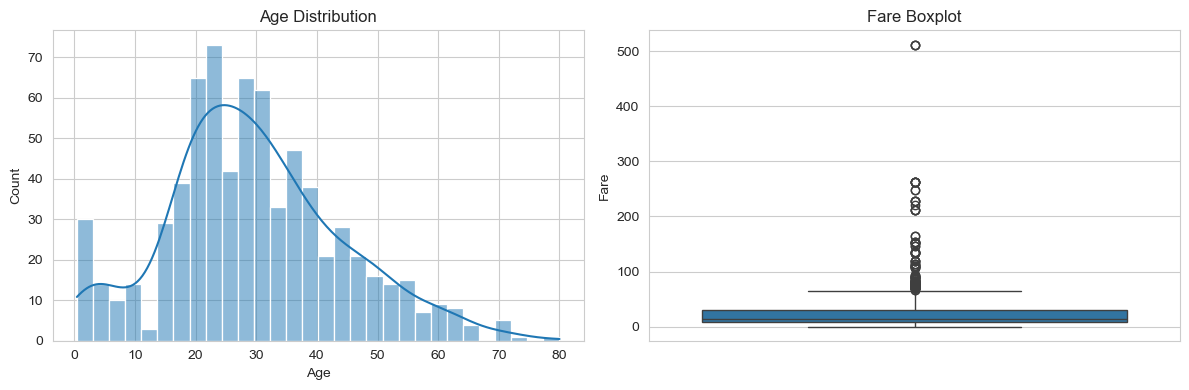

In [49]:
# EXAMPLE (continued): numeric distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Age'].dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')

sns.boxplot(y=df['Fare'], ax=axes[1])
axes[1].set_title('Fare Boxplot')
plt.tight_layout()
plt.show()


### Task 11
1. Print the value counts (as proportions) of the `Embarked` column.
2. Plot a histogram of the `Fare` column (try `bins=40`).
3. Plot a boxplot of the `Age` column.

<Axes: >

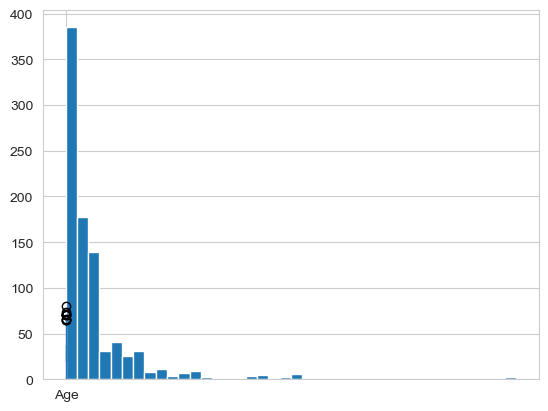

In [50]:
# TODO: value_counts(normalize=True) on Embarked
df['Embarked'].value_counts(normalize=True)
# TODO: histogram of Fare (bins=40)
df['Fare'].hist(bins=40)
# TODO: boxplot of Age
df['Age'].plot(kind='box')

## 12. Bivariate EDA (Exploring Relationships Between Variables)

### Theory
- `pd.crosstab(col1, col2)` — frequency table between two categorical columns (add `normalize='index'` for row percentages)
- `df.groupby(col)['other'].mean()` — average of a numeric column per category
- `df.corr(numeric_only=True)` — correlation matrix between numeric columns
- `sns.heatmap()` — visualize a correlation matrix
- `sns.barplot()` / `sns.scatterplot()` — visualize categorical-vs-numeric or numeric-vs-numeric relationships


In [51]:
# EXAMPLE
ct = pd.crosstab(df['Sex'], df['Survived'], normalize='index').round(2)
print(ct)


Survived     0     1
Sex                 
female    0.26  0.74
male      0.81  0.19


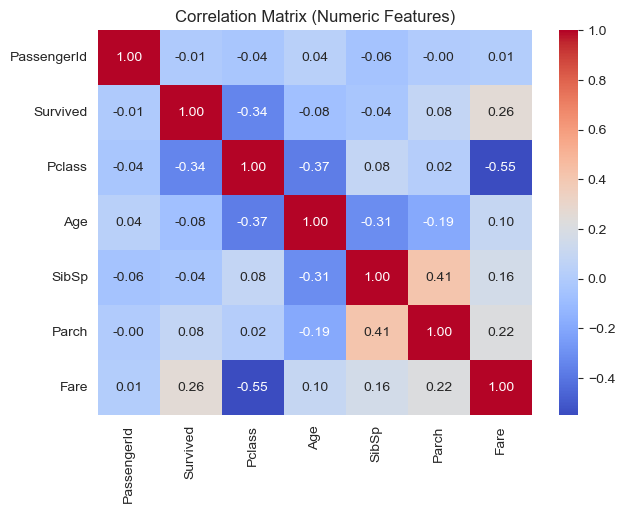

In [52]:
# EXAMPLE (continued): correlation heatmap
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix (Numeric Features)')
plt.show()


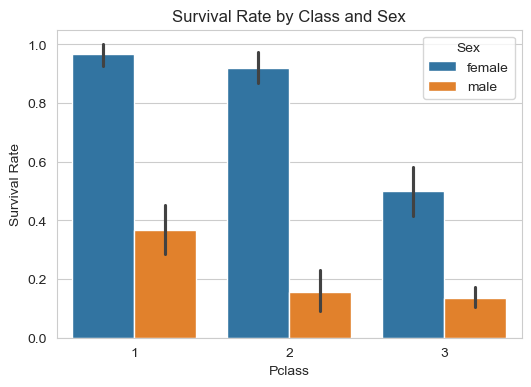

In [53]:
# EXAMPLE (continued): barplot -- survival rate by class and sex
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex')
plt.title('Survival Rate by Class and Sex')
plt.ylabel('Survival Rate')
plt.show()


### Task 12
1. Build a crosstab of `Pclass` vs `Survived`, normalized by row (`normalize='index'`).
2. Create a scatter plot of `Age` (x-axis) vs `Fare` (y-axis), colored by `Survived` (hint: `sns.scatterplot(..., hue='Survived')`).
3. In one sentence (as a markdown comment or `print()`), state what relationship (if any) you observe between class and survival.

Passengers in higher Pclass tend to have higher survival rates.


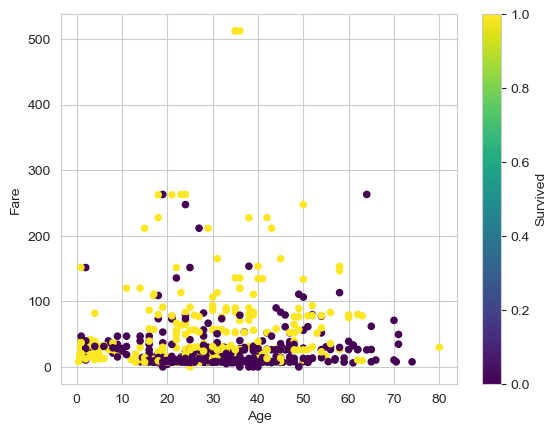

In [54]:
# TODO: crosstab of Pclass vs Survived, normalized by row
pd.crosstab(df['Pclass'], df['Survived'], normalize='index')
# TODO: scatterplot of Age vs Fare, colored by Survived
df.plot.scatter(x='Age', y='Fare', c='Survived', colormap='viridis')

# TODO: print() a one-sentence observation
print("Passengers in higher Pclass tend to have higher survival rates.")

## 13. Outlier Detection (IQR Method)

### Theory
A common rule of thumb for flagging outliers in a numeric column uses the **Interquartile Range (IQR)**:

```
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
```

Any value outside `[lower_bound, upper_bound]` is considered a potential outlier. This is exactly what a boxplot visualizes (the whiskers mark these bounds).


In [55]:
# EXAMPLE
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Fare'] < lower_bound) | (df['Fare'] > upper_bound)]
print(f"IQR bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Number of Fare outliers: {len(outliers)}")
outliers[['Name', 'Fare', 'Pclass']].sort_values('Fare', ascending=False).head()


IQR bounds: [-26.72, 65.63]
Number of Fare outliers: 116


,Name,Fare,Pclass
679,"Cardeza, Mr. Thomas Drake Martinez",512.3292,1
258,"Ward, Miss. Anna",512.3292,1
737,"Lesurer, Mr. Gustave J",512.3292,1
341,"Fortune, Miss. Alice Elizabeth",263.0000,1
438,"Fortune, Mr. Mark",263.0000,1


### Task 13
1. Compute the IQR-based lower and upper bounds for the `Age` column.
2. Count and display how many passengers fall outside those bounds.
3. (Optional/discussion) Would you drop these outliers or keep them? Write your reasoning in a `print()` statement or markdown note.

In [57]:
# TODO: compute IQR bounds for Age
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# TODO: filter and count Age outliers
age_outliers = df[(df["Age"] < lower_bound) | (df["Age"] > upper_bound)]
print("Number of Age outliers:", len(age_outliers))

# TODO: your reasoning
print("I would keep these outliers because unusually young or old passengers are plausible values,")
print("and removing them could discard legitimate information rather than correcting data errors.")

Lower bound: -6.6875
Upper bound: 64.8125
Number of Age outliers: 11
I would keep these outliers because unusually young or old passengers are plausible values,
and removing them could discard legitimate information rather than correcting data errors.


## 14. Wrap-Up: Putting It All Together

### Theory
A typical end-to-end data preparation + EDA workflow looks like:

1. Load data → `pd.read_csv()`
2. Inspect → `.head()`, `.info()`, `.describe()`
3. Clean → handle missing values, duplicates, fix dtypes
4. Transform/engineer features → `apply`, `map`, `cut`/`qcut`
5. Explore univariately → `value_counts()`, histograms, boxplots
6. Explore bivariately → `groupby()`, `crosstab()`, correlation, scatter/bar plots
7. Flag/handle outliers
8. Summarize findings before modeling

### Final Task
Using everything from this notebook, produce a **cleaned, feature-engineered version of the Titanic dataset** called `df_final` that:
- Has no missing values in `Age`, `Embarked`, or `Fare`
- Drops the `Cabin` column
- Includes the engineered columns `FamilySize`, `IsAlone`, `Title`, and `AgeGroup`
- Has appropriate dtypes (categorical columns converted to `category`)

Then print `df_final.info()` to confirm your work, and write 2–3 sentences summarizing the most interesting pattern you found in your EDA (e.g., about survival vs. class, sex, age, or fare).

In [58]:
# TODO: build df_final following the requirements above
df_final = df.copy()

# TODO: df_final.info()
# Fill missing values
df_final["Age"] = df_final["Age"].fillna(df_final["Age"].median())
df_final["Embarked"] = df_final["Embarked"].fillna(df_final["Embarked"].mode()[0])
df_final["Fare"] = df_final["Fare"].fillna(df_final["Fare"].median())

# Feature engineering
df_final["FamilySize"] = df_final["SibSp"] + df_final["Parch"] + 1
df_final["IsAlone"] = (df_final["FamilySize"] == 1).astype(int)

# Extract title from Name
df_final["Title"] = df_final["Name"].str.extract(r",\s*([^.]*)\.", expand=False)

# Group uncommon titles
common_titles = ["Mr", "Miss", "Mrs", "Master"]
df_final["Title"] = df_final["Title"].where(
    df_final["Title"].isin(common_titles), "Other"
)

# Create age groups
df_final["AgeGroup"] = pd.cut(
    df_final["Age"],
    bins=[0, 12, 18, 35, 60, float("inf")],
    labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"]
)
# TODO: 2-3 sentence summary of your most interesting EDA finding (as a print() or in a markdown cell below)
# Drop Cabin
df_final = df_final.drop(columns=["Cabin"])

# Convert categorical columns to category dtype
categorical_cols = df_final.select_dtypes(include=["object"]).columns
df_final[categorical_cols] = df_final[categorical_cols].astype("category")

# Also make engineered categorical columns category
df_final["Title"] = df_final["Title"].astype("category")
df_final["AgeGroup"] = df_final["AgeGroup"].astype("category")

# Confirm the result
df_final.info()

print(
    "The EDA showed that passenger class and sex were strongly related to survival. "
    "Female passengers and passengers in higher classes had substantially higher survival rates. "
    "Age and fare also showed useful differences in survival patterns."
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    category
 4   Sex          891 non-null    category
 5   Age          891 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    category
 9   Fare         891 non-null    float64 
 10  Embarked     891 non-null    category
 11  FareGroup    891 non-null    category
 12  FamilySize   891 non-null    int64   
 13  IsAlone      891 non-null    int64   
 14  Title        891 non-null    category
 15  AgeGroup     891 non-null    category
dtypes: category(7), float64(2), int64(7)
memory usage: 132.2 KB
The EDA showed that passenger class and sex were strongl

---
### Congratulations!
You've walked through the full pandas data preparation and EDA workflow: loading, inspecting, cleaning, transforming, and exploring data both univariately and bivariately, plus basic outlier detection. These same steps apply to virtually any tabular dataset you'll work with in data science.